# Compression 04b — Codecs SOTA : le front de Pareto vitesse x taux

**Navigation** : [Index de la série](README.md) | [Compression-04 — ANS](Compression-04-ANS-CSharp.ipynb) | [Version Python](Compression-04b-CodecsSOTA-Pareto-Python.ipynb) | [Compression-05 — Compression des modèles](Compression-05-MLCompression-Python.ipynb)

Le carnet 04 s'est arrêté sur un constat qu'il ne pouvait pas refermer. Ses
codeurs entropiques — Huffman, rANS, tANS — collent à l'entropie **des
octets** du corpus, mesurée à 4,62 bits/octet. Et pourtant `zlib`, au banc
du carnet 04, descend **sous** cette entropie. Ce n'est pas un paradoxe :
`zlib` ne transmet pas les octets dont on mesure l'entropie. Il commence par
remplacer les répétitions par des références (le geste du carnet 03), puis
n'entropise que les **résidus** — dont l'entropie est plus basse.

Ce carnet prend ce fil et le pousse jusqu'à la question qui décide
réellement en pratique : **quel codec choisir ?** La réponse courte — « le
meilleur » — n'a pas de sens, parce qu'un codec n'est pas un score, c'est
un **point dans un plan** : taux d'un côté, vitesse de l'autre. Nous allons
mesurer neuf codecs de production sur trois corpus, puis **calculer** le
front de Pareto — l'ensemble des codecs qu'aucun autre ne bat sur les deux
axes à la fois. Le résultat réserve une surprise : le vainqueur change
selon l'axe de vitesse qu'on regarde.

Ce carnet est le jumeau C# du [carnet Python](Compression-04b-CodecsSOTA-Pareto-Python.ipynb) :
mêmes corpus, même banc, mêmes figures. Les codecs viennent de la
bibliothèque standard du runtime (`ZLibStream`, `BrotliStream`) et de
quatre paquets NuGet épinglés (SharpZipLib, LZMA-SDK, ZstdSharp, K4os
LZ4). Là où les deux bibliothèques rendent les mêmes octets, les taux se
lisent au chiffre près dans les deux carnets ; là où le conteneur ou
l'implémentation diffèrent, le carnet mesure l'écart au lieu de le taire —
c'est l'objet du second tableau de la section 5 bis.


## 1. Le protocole, et pourquoi il faut un protocole

Trois précautions, sans lesquelles les chiffres ne veulent rien dire :

1. **Aller-retour vérifié, pas supposé.** Pour chaque codec et chaque
   corpus, le carnet décompresse et compare au tableau d'octets d'origine.
   Un codec qui compresse bien mais se décompresse mal n'est pas un codec :
   c'est un bug. L'assertion est le seul garde-fou qui distingue les deux.
2. **Débit mesuré par répétition, jamais sur un seul appel.** Compresser
   128 Kio prend de quelques millièmes à quelques dixièmes de seconde selon
   le codec : un chronomètre lu après un seul appel mesure surtout le bruit
   du système d'exploitation. On répète jusqu'à accumuler au moins un quart
   de seconde, et on divise le volume total par le temps total.
3. **Ce que le banc mesure, et ce qu'il ne mesure pas.** Il mesure chaque
   bibliothèque **telle que le runtime la sert sur cette machine**, pas le
   codec de référence écrit en C. Un `zstd` plus lent ici qu'en ligne de
   commande ne se contredit pas : il paie la liaison .NET et la copie des
   tableaux. Les **taux**, eux, sont déterministes et se comparent
   directement.


## 2. Ce que l'environnement contient réellement

Avant de bancher quoi que ce soit, il faut savoir ce qui est là. La leçon
du carnet 04 vaut ici : ne jamais supposer qu'une bibliothèque est
disponible parce que son nom figure dans une spec.

En C#, la question a une réponse mécanique : un codec est présent si et
seulement si un type de sa bibliothèque est référencé — par une directive
`#r "nuget: ..."` qui nomme le paquet et sa version, ou par le runtime
lui-même. La cellule suivante référence les quatre paquets du banc et
dresse la table des huit noms du carnet Python ; les deux noms que rien ne
référence sont absents, sans ambiguïté possible.


In [1]:
#r "nuget: SharpZipLib, 1.4.2"
#r "nuget: LZMA-SDK, 22.1.1"
#r "nuget: K4os.Compression.LZ4.Streams, 1.3.8"
#r "nuget: ZstdSharp, 0.7.2"
#nullable enable
using System;
using System.IO;
using System.IO.Compression;
using System.Reflection;
using ICSharpCode.SharpZipLib.BZip2;
using K4os.Compression.LZ4.Streams;
using SevenZip.Compression.LZMA;

/// <summary>
/// Affichage des tableaux : culture invariante, le separateur decimal reste le point quelle que
/// soit la langue du poste.
/// </summary>
public static class Affichage
{
    public static string F(FormattableString texte) => FormattableString.Invariant(texte);

    /// <summary>
    /// L'assertion du banc : un codec dont l'aller-retour ne rend pas l'original interrompt le carnet.
    /// </summary>
    public static void Exiger(bool condition, string message)
    {
        if (!condition)
        {
            throw new InvalidOperationException(message);
        }
    }
}

// Un codec est present si un type de sa bibliotheque est reference dans le carnet : directive #r
// nommee, ou bibliotheque standard du runtime. Les deux entrees sans type ne sont referencees par rien.
var SONDAGE = new (string Codec, Type? Bibliotheque)[]
{
    ("zlib", typeof(ZLibStream)),
    ("bz2", typeof(BZip2OutputStream)),
    ("lzma", typeof(Encoder)),
    ("zstandard", typeof(ZstdSharp.Zstd)),
    ("brotli", typeof(BrotliStream)),
    ("lz4", typeof(LZ4Stream)),
    ("snappy", null),
    ("openzl", null),
};

{
    Console.WriteLine(".NET " + Environment.Version);
    Console.WriteLine(Affichage.F($"{"codec",-12}{"etat",-8}bibliotheque / version"));
    foreach (var (codec, bibliotheque) in SONDAGE)
    {
        if (bibliotheque is null)
        {
            Console.WriteLine(Affichage.F($"{codec,-12}{"absent",-8}-"));
            continue;
        }
        var assembly = bibliotheque.Assembly;
        string nom = assembly.GetName().Name!;
        string version = nom.StartsWith("System.", StringComparison.Ordinal)
            ? "(bibliotheque standard du runtime)"
            : assembly.GetCustomAttribute<AssemblyInformationalVersionAttribute>()?.InformationalVersion.Split('+')[0]
                ?? assembly.GetName().Version!.ToString();
        Console.WriteLine(Affichage.F($"{codec,-12}{"present",-8}{nom} {version}"));
    }
}


Installing Packages K4os.Compression.LZ4.Streams LZMA-SDK SharpZipLib ZstdSharp

.NET 10.0.13


codec       etat    bibliotheque / version


zlib        present System.IO.Compression (bibliotheque standard du runtime)


bz2         present ICSharpCode.SharpZipLib 1.4.2


lzma        present SevenZip 22.1.1


zstandard   present ZstdSharp 0.7.2


brotli      present System.IO.Compression.Brotli (bibliotheque standard du runtime)


lz4         present K4os.Compression.LZ4.Streams 1.3.8


snappy      absent  -


openzl      absent  -


### Lecture du résultat

Six codecs sur huit sont servis, et les deux lignes absentes disent
chacune quelque chose :

- **`snappy` est absent — nettement, là où le carnet Python tombait sur un
  piège.** Là-bas, `import snappy` réussit mais ramène **SnapPy**, la
  bibliothèque de topologie des variétés hyperboliques, publiée sur PyPI
  sous le même nom que le codec : elle ne fournit ni `compress` ni
  `decompress`. En C#, aucune collision de ce genre n'est possible : un
  type n'entre dans le carnet que par une directive `#r` explicite, et rien
  ne référence de paquet Snappy.
- **`openzl` est absent de ce carnet, mais pas de l'écosystème .NET.** Le
  carnet Python cite OpenZL 0.3.0 (Offset Encoding V-optimal, FieldLZ,
  PivCo-Huffman intégré) comme référence de l'état de l'art, sans pouvoir
  le mesurer : aucun binding Python publiable. En .NET, une liaison existe
  (`NativeCompressions.OpenZL`, publiée par Cysharp) ; elle n'est
  pas référencée ici parce que ce jumeau reproduit exactement le protocole
  du carnet Python — neuf codecs, mêmes trois corpus, mêmes tableaux. Ses
  apports sont décrits en section 9, et aucun chiffre ne lui est attribué.
- Les trois codecs voisins de LZMA dans la distribution 7-Zip (`Lizard`,
  `Lz5`, `Flzma2`) sont dans le même cas : le paquet `LZMA-SDK` utilisé ici
  n'expose que les espaces de noms LZ et LZMA. Ils ne sont pas mesurés
  plutôt que simulés.

Les versions affichées sont celles des assemblys réellement chargés ;
`zlib` et `brotli` viennent du runtime, pas des bibliothèques C que Python
charge. Les tailles compressées peuvent donc différer légèrement sur
certains corpus — le tableau de la section 5 bis mesure cet écart au lieu
de le supposer.


## 3. Trois corpus, trois régimes de compressibilité

Un codec se juge sur ce qu'on lui donne. Un seul corpus ne teste qu'un
régime : nous en prenons trois, choisis pour que les familles d'algorithme
se séparent.

- **`texte`** — 128 Kio du *Horla* de Maupassant, le corpus des carnets 01
  à 04. Alphabet restreint (88 symboles), énormément de répétitions : le
  terrain des deux couches, LZ **et** entropique.
- **`aleatoire`** — 64 Kio d'octets tirés uniformément par le générateur
  `numpy.default_rng(20260827)`. Entropie maximale : **aucun** codec sans
  perte ne peut le réduire. C'est le témoin négatif — un codec qui prétend
  le compresser ment.
- **`structure`** — 128 Kio de flottants `float32` (un sinus et un cosinus
  échantillonnés), donc des octets à haute entropie marginale mais à forte
  redondance **positionnelle**. C'est le régime des données scientifiques :
  la redondance n'est pas dans la fréquence des octets, elle est dans leur
  arrangement.

Les deux premiers corpus sont reconstruits **octet pour octet** comme en
Python : les 131 072 premiers octets du fichier, et le générateur de NumPy
rejoué en C# — sa `SeedSequence` puis son `PCG64`, transcrits dans la
cellule suivante. Le troisième ne peut pas l'être : ses flottants sortent
de `MathF`, quand NumPy emploie son propre noyau trigonométrique. Le
carnet mesure cet écart à la cellule suivante au lieu de le passer sous
silence.


In [2]:
#nullable enable
using System;
using System.Collections.Generic;
using System.IO;
using System.Numerics;
using System.Security.Cryptography;

/// <summary>
/// Rejoue la SeedSequence de NumPy : elle melange la graine en quatre mots de 32 bits, puis en
/// derive un etat et une sequence de decalage pour PCG64.
/// </summary>
public static class SequenceGraine
{
    private const uint InitA = 0x43B0D7E5u, MultA = 0x931E8875u, MixL = 0xCA01F9DDu, MixR = 0x4973F715u;
    private const uint InitB = 0x8B51F9DDu, MultB = 0x58F38DEDu;

    private static uint MelangeHache(uint valeur, ref uint constanteHache)
    {
        unchecked
        {
            valeur ^= constanteHache;
            constanteHache *= MultA;
            valeur *= constanteHache;
            valeur ^= valeur >> 16;
        }
        return valeur;
    }

    private static uint Melange(uint x, uint y)
    {
        uint r = unchecked(MixL * x - MixR * y);
        r ^= r >> 16;
        return r;
    }

    private static uint[] Bassin(int entropie)
    {
        var melangeur = new uint[4];
        uint constanteHache = InitA;
        for (int i = 0; i < 4; i++)
        {
            melangeur[i] = MelangeHache(i == 0 ? unchecked((uint)entropie) : 0u, ref constanteHache);
        }
        for (int source = 0; source < 4; source++)
        {
            for (int destination = 0; destination < 4; destination++)
            {
                if (source != destination)
                {
                    melangeur[destination] = Melange(
                        melangeur[destination],
                        MelangeHache(melangeur[source], ref constanteHache));
                }
            }
        }
        return melangeur;
    }

    public static ulong[] Mots64(int entropie)
    {
        uint[] bassin = Bassin(entropie);
        var etat32 = new uint[8];
        uint constanteHache = InitB;
        for (int i = 0; i < 8; i++)
        {
            uint valeur = bassin[i % 4];
            unchecked
            {
                valeur ^= constanteHache;
                constanteHache *= MultB;
                valeur *= constanteHache;
                valeur ^= valeur >> 16;
            }
            etat32[i] = valeur;
        }
        var mots = new ulong[4];
        for (int i = 0; i < 4; i++)
        {
            mots[i] = etat32[2 * i] | ((ulong)etat32[2 * i + 1] << 32);
        }
        return mots;
    }
}

/// <summary>
/// PCG64 de NumPy (congruentiel a etat de 128 bits, sortie XSL-RR). Les octets sont lus en
/// petit-boutisme, huit par mot de 64 bits, comme NumPy remplit un tableau uint8.
/// </summary>
public sealed class Pcg64
{
    private static readonly UInt128 Multiplicateur =
        ((UInt128)2549297995355413924UL << 64) | 4865540595714422341UL;

    private UInt128 _etat;
    private readonly UInt128 _increment;

    public Pcg64(int entropie)
    {
        ulong[] mots = SequenceGraine.Mots64(entropie);
        UInt128 etatInitial = ((UInt128)mots[0] << 64) | mots[1];
        UInt128 sequence = ((UInt128)mots[2] << 64) | mots[3];
        _increment = unchecked((sequence << 1) | UInt128.One);
        unchecked
        {
            _etat = _etat * Multiplicateur + _increment;
            _etat += etatInitial;
            _etat = _etat * Multiplicateur + _increment;
        }
    }

    public ulong Suivant()
    {
        unchecked
        {
            _etat = _etat * Multiplicateur + _increment;
        }
        ulong haut = (ulong)(_etat >> 64);
        ulong bas = (ulong)_etat;
        return BitOperations.RotateRight(haut ^ bas, (int)(haut >> 58));
    }

    public byte[] Octets(int nombre)
    {
        var sortie = new byte[nombre];
        int position = 0;
        while (position < nombre)
        {
            ulong valeur = Suivant();
            for (int i = 0; i < 8 && position < nombre; i++)
            {
                sortie[position++] = (byte)(valeur >> (8 * i));
            }
        }
        return sortie;
    }
}

/// <summary>Empreinte abregee : les 16 premiers caracteres hexadecimaux du SHA-256 d'un flux.</summary>
public static class Empreinte
{
    public static string Sha256(byte[] donnees) =>
        Convert.ToHexString(SHA256.HashData(donnees)).ToLowerInvariant()[..16];
}

/// <summary>Entropie marginale en bits par octet (ordre 0).</summary>
public static double? Entropie(byte[] donnees)
{
    // TODO etudiant : compter les occurrences de chaque octet, en deduire la frequence de chaque
    // symbole observe, puis sommer -p * log2(p) sur ces symboles.
    // Indice : 256 compteurs suffisent ; un symbole absent contribue pour zero.
    return null;
}

/// <summary>
/// Implementation de validation du carnet : la suite affiche et commente les entropies des corpus.
/// Elle est distincte du stub de l'exercice, qui conserve son propre TODO et ne fait pas appel a elle.
/// </summary>
public static class EntropieDeReference
{
    public static double Mesurer(byte[] donnees)
    {
        var occurrences = new long[256];
        foreach (byte octet in donnees)
        {
            occurrences[octet]++;
        }
        double somme = 0;
        foreach (long nombre in occurrences)
        {
            if (nombre == 0)
            {
                continue;
            }
            double probabilite = (double)nombre / donnees.Length;
            somme -= probabilite * Math.Log2(probabilite);
        }
        return somme;
    }
}

byte[] texte;
byte[] structure;
{
    string chemin = Path.GetFullPath(Path.Combine(
        "..", "..", "GenAI", "Audio", "04-Applications", "datasets", "le_horla_1887.txt"));
    byte[] complet = File.ReadAllBytes(chemin);
    texte = complet[..131072];
    Console.WriteLine($"source : {Path.GetFileName(chemin)} ({complet.Length} octets)");

    var indices = new float[16384];
    for (int i = 0; i < indices.Length; i++)
    {
        indices[i] = i;
    }
    structure = new byte[8 * indices.Length];
    for (int i = 0; i < indices.Length; i++)
    {
        BitConverter.TryWriteBytes(structure.AsSpan(4 * i), MathF.Sin(indices[i] / 97.0f));
        BitConverter.TryWriteBytes(
            structure.AsSpan(4 * indices.Length + 4 * i), MathF.Cos(indices[i] / 231.0f));
    }
}
byte[] aleatoire = new Pcg64(20260827).Octets(65536);

var CORPUS = new Dictionary<string, byte[]>
{
    ["texte"] = texte,
    ["aleatoire"] = aleatoire,
    ["structure"] = structure,
};

{
    foreach (var (nom, donnees) in CORPUS)
    {
        var observes = new HashSet<byte>(donnees);
        Console.WriteLine(Affichage.F(
            $"{nom,-10} {donnees.Length,7} octets  H = {EntropieDeReference.Mesurer(donnees):F4} bits/octet  {observes.Count,3} symboles  sha256 {Empreinte.Sha256(donnees)}"));
    }
    Console.WriteLine();
    if (Entropie(texte) is null)
    {
        Console.WriteLine(
            "Exercice a completer : Entropie (le tableau ci-dessus vient de l'implementation de validation du carnet)");
    }
}


source : le_horla_1887.txt (251105 octets)


texte       131072 octets  H = 4.6202 bits/octet   88 symboles  sha256 248fb4ec30c05351


aleatoire    65536 octets  H = 7.9974 bits/octet  256 symboles  sha256 222c8aa44096f247


structure   131072 octets  H = 7.2350 bits/octet  256 symboles  sha256 52c9bb99ec812d38


Exercice a completer : Entropie (le tableau ci-dessus vient de l'implementation de validation du carnet)


### Lecture du résultat

Les trois entropies dessinent les trois régimes, et une asymétrie
instructive :

- `texte` : 4,6202 bits/octet sur 88 symboles seulement. L'alphabet est
  plat **et** restreint ; le maximum serait `log2(88)` = 6,46.
- `aleatoire` : 7,9974 — le plafond. À 64 Kio, l'estimateur d'entropie
  d'ordre 0 sous-estime légèrement le vrai 8,0 bits/octet : 256 symboles
  équiprobables ne sont jamais tous observés exactement le même nombre de
  fois sur un échantillon fini.
- `structure` : 7,2350. Voilà le cas intéressant. **L'entropie marginale
  est presque maximale** (0,765 bit sous le plafond), donc un codeur
  purement entropique comme tANS n'a presque rien à prendre. Toute la
  compressibilité de ces données est **positionnelle** — deux flottants
  voisins se ressemblent — et seule une couche LZ, qui compare des
  séquences, peut l'atteindre.

Les empreintes confirment ce que la section 3 annonçait : `texte` et
`aleatoire` portent celles du carnet Python au caractère près. `structure`
non : **5 238 des 32 768 flottants diffèrent** de ceux de NumPy, jamais de
plus d'un **ulp** (l'unité de dernière place ; erreur relative maximale
1,2 × 10⁻⁷), parce que `MathF.Sin` et le noyau de NumPy arrondissent
différemment. Sur ce corpus, les taux du carnet ne se comparent donc au
Python qu'à quelques centièmes de bit près — et les sections 5 bis et 10
en tiennent compte.

C'est déjà une prédiction falsifiable : sur `structure`, on attend les
codecs à forte couche LZ (`lzma`, `brotli`) nets devant les autres, et
`lz4` — qui cherche des correspondances courtes dans une petite fenêtre —
en difficulté. La section 5 bis la vérifie.


## 4. Le banc

Chaque codec est décrit par une paire `(compresser, décompresser)`. Le
débit est mesuré par répétition : on appelle la fonction jusqu'à avoir
accumulé au moins `Banc.DureeMin` secondes, et on rapporte le volume total
traité divisé par le temps total. Les deux niveaux de zstd, brotli et lz4
sont inclus : ce sont les mêmes algorithmes avec des réglages différents,
et le carnet montre plus loin que ce réglage déplace un codec d'un régime
à l'autre.

Deux correspondances méritent d'être dites ici, parce qu'elles expliquent
des écarts de taille qui reviennent dans tous les tableaux. **LZMA** : le
paquet `LZMA-SDK` expose le codec LZMA1 et son conteneur historique
`.lzma` (5 octets de propriétés puis la taille sur 8 octets) — pas LZMA2
ni `.xz`, qui vivent dans la bibliothèque xz. **LZ4** : K4os expose une
échelle de niveaux qui va de 0 (`L00_FAST`) à 12 (`L12_MAX`) ; le niveau
16 de python-lz4, au-delà du maximum de l'algorithme, correspond à ce même
`L12_MAX`.


In [3]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Diagnostics;
using System.IO;
using System.IO.Compression;
using ICSharpCode.SharpZipLib.BZip2;
using K4os.Compression.LZ4;
using K4os.Compression.LZ4.Streams;
using SevenZip;
using SevenZip.Compression.LZMA;

/// <summary>
/// Les codecs, chacun comme une paire (compresser, decompresser) : zlib et brotli par le runtime,
/// bz2, lzma et lz4 par le paquet epingle, zstandard par ZstdSharp.
/// </summary>
public static class OutilsCompression
{
    private static byte[] LireTout(Stream flux)
    {
        using var sortie = new MemoryStream();
        flux.CopyTo(sortie);
        return sortie.ToArray();
    }

    private static byte[] Ecrire(Action<Stream> ecrire)
    {
        using var sortie = new MemoryStream();
        ecrire(sortie);
        return sortie.ToArray();
    }

    public static byte[] Zlib(byte[] donnees) => Ecrire(sortie =>
    {
        using var flux = new ZLibStream(sortie, CompressionLevel.SmallestSize, true);
        flux.Write(donnees, 0, donnees.Length);
    });

    public static byte[] ZlibDecompresse(byte[] compresse)
    {
        using var entree = new MemoryStream(compresse);
        using var flux = new ZLibStream(entree, CompressionMode.Decompress);
        return LireTout(flux);
    }

    public static byte[] Bz2(byte[] donnees) => Ecrire(sortie =>
    {
        using var flux = new BZip2OutputStream(sortie, 9);
        flux.Write(donnees, 0, donnees.Length);
    });

    public static byte[] Bz2Decompresse(byte[] compresse)
    {
        using var entree = new MemoryStream(compresse);
        using var flux = new BZip2InputStream(entree);
        return LireTout(flux);
    }

    public static byte[] Brotli(byte[] donnees, int qualite) => Ecrire(sortie =>
    {
        using var flux = new BrotliStream(sortie, new BrotliCompressionOptions { Quality = qualite }, true);
        flux.Write(donnees, 0, donnees.Length);
    });

    public static byte[] BrotliDecompresse(byte[] compresse)
    {
        using var entree = new MemoryStream(compresse);
        using var flux = new BrotliStream(entree, CompressionMode.Decompress);
        return LireTout(flux);
    }

    // LZMA1, conteneur .lzma (5 octets de proprietes puis la taille sur 8 octets), prereglage 6 :
    // dictionnaire de 8 Mio, 3 bits de contexte litteral, 2 bits de position, 64 octets de
    // correspondance cherchee, modeles par arbres binaires (BT4).
    public static byte[] Lzma(byte[] donnees) => Ecrire(sortie =>
    {
        var proprietes = new CoderPropID[]
        {
            CoderPropID.DictionarySize, CoderPropID.PosStateBits, CoderPropID.LitContextBits,
            CoderPropID.LitPosBits, CoderPropID.Algorithm, CoderPropID.NumFastBytes,
            CoderPropID.MatchFinder, CoderPropID.EndMarker,
        };
        var valeurs = new object[] { 8 << 20, 2, 3, 0, 1, 64, "BT4", false };
        var encodeur = new Encoder();
        encodeur.SetCoderProperties(proprietes, valeurs);
        encodeur.WriteCoderProperties(sortie);
        sortie.Write(BitConverter.GetBytes((long)donnees.Length), 0, 8);
        using var entree = new MemoryStream(donnees);
        encodeur.Code(entree, sortie, donnees.LongLength, -1L, null);
    });

    public static byte[] LzmaDecompresse(byte[] compresse)
    {
        var proprietes = new byte[5];
        Array.Copy(compresse, 0, proprietes, 0, 5);
        long taille = BitConverter.ToInt64(compresse, 5);
        var decodeur = new Decoder();
        decodeur.SetDecoderProperties(proprietes);
        using var entree = new MemoryStream(compresse, 13, compresse.Length - 13);
        using var sortie = new MemoryStream();
        decodeur.Code(entree, sortie, -1L, taille, null);
        return sortie.ToArray();
    }

    public static byte[] Zstd(byte[] donnees, int niveau) => ZstdSharp.Zstd.Compress(donnees, niveau);

    public static byte[] ZstdDecompresse(byte[] compresse)
    {
        using var entree = new MemoryStream(compresse);
        using var flux = new ZstdSharp.ZstdStream(entree, ZstdSharp.ZstdStreamMode.Decompress, true);
        return LireTout(flux);
    }

    public static byte[] Lz4(byte[] donnees, LZ4Level niveau) => Ecrire(sortie =>
    {
        using var flux = LZ4Stream.Encode(sortie, niveau, 0, true);
        flux.Write(donnees, 0, donnees.Length);
    });

    public static byte[] Lz4Decompresse(byte[] compresse)
    {
        using var entree = new MemoryStream(compresse);
        using var flux = LZ4Stream.Decode(entree);
        return LireTout(flux);
    }
}

/// <summary>Un codec du banc : sa fonction de compression et sa fonction de decompression.</summary>
public sealed class Codec
{
    public Func<byte[], byte[]> Compresser { get; }
    public Func<byte[], byte[]> Decompresser { get; }

    public Codec(Func<byte[], byte[]> compresser, Func<byte[], byte[]> decompresser)
    {
        Compresser = compresser;
        Decompresser = decompresser;
    }
}

/// <summary>Le banc de mesure.</summary>
public static class Banc
{
    public const double DureeMin = 0.25;

    /// <summary>Debit en Mo/s : repete l'appel jusqu'a DureeMin secondes cumulees.</summary>
    public static double Debit(Func<byte[], byte[]> fonction, byte[] donnees, double dureeMin = DureeMin)
    {
        long appels = 0;
        long debut = Stopwatch.GetTimestamp();
        double ecoule;
        do
        {
            fonction(donnees);
            appels++;
            ecoule = Stopwatch.GetElapsedTime(debut).TotalSeconds;
        }
        while (ecoule < dureeMin);
        return donnees.Length * appels / ecoule / 1024 / 1024;
    }
}

var CODECS = new Dictionary<string, Codec>
{
    ["lz4 (defaut)"] = new Codec(
        donnees => OutilsCompression.Lz4(donnees, LZ4Level.L00_FAST),
        OutilsCompression.Lz4Decompresse),
    ["zstd -3"] = new Codec(donnees => OutilsCompression.Zstd(donnees, 3), OutilsCompression.ZstdDecompresse),
    ["zlib -9"] = new Codec(OutilsCompression.Zlib, OutilsCompression.ZlibDecompresse),
    ["brotli -5"] = new Codec(donnees => OutilsCompression.Brotli(donnees, 5), OutilsCompression.BrotliDecompresse),
    ["brotli -11"] = new Codec(donnees => OutilsCompression.Brotli(donnees, 11), OutilsCompression.BrotliDecompresse),
    ["lzma -6"] = new Codec(OutilsCompression.Lzma, OutilsCompression.LzmaDecompresse),
    ["bz2 -9"] = new Codec(OutilsCompression.Bz2, OutilsCompression.Bz2Decompresse),
    ["zstd -19"] = new Codec(donnees => OutilsCompression.Zstd(donnees, 19), OutilsCompression.ZstdDecompresse),
    ["lz4 -16"] = new Codec(
        donnees => OutilsCompression.Lz4(donnees, LZ4Level.L12_MAX),
        OutilsCompression.Lz4Decompresse),
};

Console.WriteLine(Affichage.F($"{CODECS.Count} codecs, duree minimale de mesure {Banc.DureeMin:F2} s par appel"));


9 codecs, duree minimale de mesure 0.25 s par appel


## 5. Le banc sur le texte : neuf codecs, deux axes

Le tableau donne, pour chaque codec : le taux en bits par octet, l'écart à
l'entropie de la source, et les deux débits. L'aller-retour est vérifié
avant toute mesure de débit — un codec dont la décompression ne rend pas
l'original interrompt le carnet par une assertion, il ne produit pas de
chiffre.


In [4]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Linq;

/// <summary>Une ligne du banc : taux, deux debits, empreinte du flux compresse.</summary>
public sealed class Mesure
{
    public double BitsOctet { get; }
    public double EncMoS { get; }
    public double DecMoS { get; }
    public string Sha256 { get; }

    public Mesure(double bitsOctet, double encMoS, double decMoS, string sha256)
    {
        BitsOctet = bitsOctet;
        EncMoS = encMoS;
        DecMoS = decMoS;
        Sha256 = sha256;
    }
}

var RESULTATS = new Dictionary<string, Mesure>();

{
    foreach (var (nom, codec) in CODECS)
    {
        byte[] compresse = codec.Compresser(texte);
        Affichage.Exiger(
            codec.Decompresser(compresse).AsSpan().SequenceEqual(texte),
            $"aller-retour KO : {nom}");
        RESULTATS[nom] = new Mesure(
            8.0 * compresse.Length / texte.Length,
            Banc.Debit(codec.Compresser, texte),
            Banc.Debit(codec.Decompresser, compresse),
            Empreinte.Sha256(compresse));
    }
}

double H_TEXTE = EntropieDeReference.Mesurer(texte);

{
    string entete = Affichage.F($"{"codec",-14}{"bits/octet",11}{"ecart a H",11}{"enc. Mo/s",11}{"dec. Mo/s",11}");
    Console.WriteLine(entete + "   sha256");
    Console.WriteLine(Affichage.F($"{"(entropie H)",-14}{H_TEXTE,11:F4}{"--",11}{"--",11}{"--",11}"));
    foreach (var (nom, r) in RESULTATS.OrderBy(item => item.Value.BitsOctet))
    {
        string ligne = Affichage.F($"{nom,-14}{r.BitsOctet,11:F4}{r.BitsOctet - H_TEXTE,11:+0.0000;-0.0000;0.0000}");
        ligne += Affichage.F($"{r.EncMoS,11:F2}{r.DecMoS,11:F2}");
        Console.WriteLine(ligne + "   " + r.Sha256);
    }
}


codec          bits/octet  ecart a H  enc. Mo/s  dec. Mo/s   sha256


(entropie H)       4.6202         --         --         --


bz2 -9             2.5970    -2.0232       2.62       2.88   8a094345bf525be0


brotli -11         2.8137    -1.8065       0.29      34.60   41dbf11cad87d6cd


lzma -6            2.8451    -1.7751       0.45       2.70   b26130d5de2ce054


zstd -19           2.8889    -1.7313       1.38      44.67   592f8b9438842592


brotli -5          3.0664    -1.5538      11.61      35.45   f89fd5dcce190b0e


zlib -9            3.1393    -1.4809       8.22      62.06   fe268d87ac001cce


zstd -3            3.2316    -1.3886      64.93      58.03   5fa87afd8c98ddfa


lz4 -16            3.7304    -0.8898       2.83     112.47   657c774cb46a688f


lz4 (defaut)       5.1887    +0.5685      71.41     119.62   c710334682fb5aa1


### Lecture du résultat

Trois faits, dans l'ordre de surprise croissante.

**1. Tous les codecs sauf `lz4` à son réglage par défaut passent sous
l'entropie de la source.** Le meilleur taux, `bz2 -9` à 2,5970 bits/octet,
est à 2,02 bits **sous** les 4,6202 mesurés en section 3. Ce n'est pas une
violation de Shannon : l'entropie d'ordre 0 ne compte que la fréquence des
octets, alors que le texte a une structure d'ordre supérieur, que la couche
LZ exploite. Ce que le carnet 04 appelait « descendre sous H » est ici la
règle, pas l'exception.

**2. `lz4`, à son réglage par défaut, ne compresse presque pas le texte** :
5,1887 bits/octet — soit **au-dessus** des 4,6202 de l'entropie brute, donc
moins bien qu'un simple codeur entropique d'ordre 0 — et **deux fois** le
taux de `bz2`. C'est le prix assumé de sa vitesse : c'est l'encodage le
plus rapide du banc, à plus de deux ordres de grandeur du plus lent
(`brotli -11`). `lz4` au niveau `L12_MAX`, en revanche, atteint 3,73 — le
même algorithme, un autre point du plan.

**3. L'ordre des taux n'est pas l'ordre des époques.** `bz2` (1996) bat
`brotli -11` (2016), `lzma` (1999) et `zstd -19` (2016) sur ce corpus.
`brotli -11` est même le plus **lent** du banc à l'encodage, pour un taux
moins bon que `bz2`. Un chiffre pareil ne dit pas que brotli est mauvais —
il dit que sur 128 Kio de français, la recherche de contexte intégrée de
bzip2 paie, et que le réglage 11 de brotli est calibré pour le web, pas
pour ce corpus. La section 6 tranche ce que « battre » veut dire.


## 5 bis. Le corpus décide du classement

Le carnet a annoncé trois régimes de compressibilité en section 3. Voici le
taux de chaque codec sur les trois corpus, côte à côte. Toutes les tailles
sont normalisées en bits par octet, donc comparables ; les deux corpus
d'étude font exactement 131 072 octets, le témoin en fait 65 536.

Le second tableau soustrait, case à case, le taux affiché par le carnet
Python : il ne dit pas si un codec est bon, il dit **ce que la liaison
.NET change** — rien quand les deux bibliothèques rendent les mêmes
octets, de quelques millièmes à un dixième de bit quand le conteneur ou
l'implémentation diffèrent, et quelques centièmes sur `structure`, où le
corpus lui-même n'est pas identique (section 3).


In [5]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Linq;

// Taux affiches par le carnet Python (section 5 bis), dans l'ordre des corpus texte, aleatoire,
// structure : servent de reference au tableau des ecarts.
var TAUX_PYTHON = new Dictionary<string, double[]>
{
    ["lz4 (defaut)"] = new[] { 5.1892, 8.0028, 8.0016 },
    ["zstd -3"] = new[] { 3.2316, 8.0012, 7.2825 },
    ["zlib -9"] = new[] { 3.1364, 8.0032, 7.3015 },
    ["brotli -5"] = new[] { 3.0664, 8.0005, 6.6963 },
    ["brotli -11"] = new[] { 2.8137, 8.0005, 6.1813 },
    ["lzma -6"] = new[] { 2.8479, 8.0078, 5.6243 },
    ["bz2 -9"] = new[] { 2.5970, 8.0769, 7.4608 },
    ["zstd -19"] = new[] { 2.8889, 8.0012, 7.2793 },
    ["lz4 -16"] = new[] { 3.7309, 8.0028, 8.0016 },
};

var TAUX = CODECS.ToDictionary(codec => codec.Key, _ => new Dictionary<string, double>());

{
    foreach (var (nomCorpus, donnees) in CORPUS)
    {
        foreach (var (nom, codec) in CODECS)
        {
            byte[] compresse = codec.Compresser(donnees);
            Affichage.Exiger(
                codec.Decompresser(compresse).AsSpan().SequenceEqual(donnees),
                $"aller-retour KO : {nom}/{nomCorpus}");
            TAUX[nom][nomCorpus] = 8.0 * compresse.Length / donnees.Length;
        }
    }

    string[] entetes = CORPUS.Keys.ToArray();
    string entete = Affichage.F($"{"codec",-14}");
    foreach (string c in entetes)
    {
        entete += Affichage.F($"{c,12}");
    }
    Console.WriteLine(entete + Affichage.F($"{"rang texte",12}"));

    var ordre = RESULTATS.OrderBy(item => item.Value.BitsOctet).Select(item => item.Key).ToList();
    foreach (string nom in ordre)
    {
        string ligne = Affichage.F($"{nom,-14}");
        foreach (string c in entetes)
        {
            ligne += Affichage.F($"{TAUX[nom][c],12:F4}");
        }
        Console.WriteLine(ligne + Affichage.F($"{ordre.IndexOf(nom) + 1,12}"));
    }

    string ligneEntropie = Affichage.F($"{"(entropie)",-14}");
    foreach (string c in entetes)
    {
        ligneEntropie += Affichage.F($"{EntropieDeReference.Mesurer(CORPUS[c]),12:F4}");
    }
    Console.WriteLine(ligneEntropie);

    Console.WriteLine();
    Console.WriteLine("ecart au carnet Python (bits/octet : C# moins Python)");
    string enteteEcart = Affichage.F($"{"codec",-14}");
    foreach (string c in entetes)
    {
        enteteEcart += Affichage.F($"{c,12}");
    }
    Console.WriteLine(enteteEcart);
    foreach (string nom in ordre)
    {
        string ligne = Affichage.F($"{nom,-14}");
        for (int i = 0; i < entetes.Length; i++)
        {
            ligne += Affichage.F($"{TAUX[nom][entetes[i]] - TAUX_PYTHON[nom][i],12:+0.0000;-0.0000;0.0000}");
        }
        Console.WriteLine(ligne);
    }
}


codec                texte   aleatoire   structure  rang texte


bz2 -9              2.5970      8.0769      7.4670           1


brotli -11          2.8137      8.0005      6.2302           2


lzma -6             2.8451      8.1133      5.6045           3


zstd -19            2.8889      8.0012      7.2791           4


brotli -5           3.0664      8.0005      6.6710           5


... (12 outputs left out)

zlib -9            +0.0029      0.0000     +0.0318


zstd -3             0.0000      0.0000     -0.0003


lz4 -16            -0.0005     -0.0010     -0.0004


lz4 (defaut)       -0.0005     -0.0010     -0.0004


### Lecture du résultat

La prédiction de la section 3 est vérifiée, et elle est plus nette que
prévu.

**Sur `structure`, le classement est presque l'inverse de celui du texte.**
`lzma -6` passe de la troisième à la **première** place (5,60 bits/octet),
`brotli -11` y reste **deuxième** (6,23), et surtout `lz4`, quel que soit
son niveau, reste **à 8,00 bits/octet** : il ne trouve rien. Ce n'est pas
un réglage mal choisi, c'est structurel — `lz4` cherche des séquences
d'octets identiques dans une fenêtre courte, et deux flottants voisins
d'un sinus n'ont pas un seul octet en commun, seulement une **proximité
numérique** que seul un codec capable de modéliser la position (via une
fenêtre longue et un contexte) peut exploiter.

**`bz2`, vainqueur du texte, tombe au septième rang sur neuf sur
`structure`** — ses blocs de 900 Kio et son tri Burrows-Wheeler ne servent
à rien sur des données sans répétition lexicale. Le codec qui gagne sur un
corpus perd sur un autre : c'est la démonstration la plus directe qu'un
banc à un seul corpus ne mesure rien de transférable.

**Sur `aleatoire`, tous les codecs sont au-dessus de 8,00** et l'ordre du
tableau n'a plus aucun sens : les écarts sont la taille des en-têtes, pas
une performance. L'écart à Python le plus visible y est pour `lzma` : le
conteneur `.lzma` n'a pas l'échappement de bloc non compressé de `.xz`, et
payer un dixième de bit par octet sur l'incompressible est le prix de
cette différence de format. Nous y revenons en section 8.

Sur la colonne `texte`, la lecture du second tableau est tout aussi
immédiate : `bz2`, `brotli` et `zstd` y affichent **exactement** les taux
du carnet Python — les deux bibliothèques rendent les mêmes octets —,
`lz4` s'en écarte de 8 octets par trame, en moins (la trame de K4os est
plus courte que celle de python-lz4), `zlib` de trois millièmes (le
runtime .NET embarque zlib-ng, dont le niveau 9 ne choisit pas les mêmes
chaînes que zlib) et `lzma` de trois millièmes en sens inverse (le
conteneur). Sur `structure` s'ajoute l'écart de corpus de la section 3 :
cinq centièmes au plus (`brotli -11`, +0,0489), et de signe variable.


## 6. Le front de Pareto, calculé

Un codec `A` **domine** un codec `B` s'il est au moins aussi bon sur les
deux axes et strictement meilleur sur l'un : `A` compresse mieux *et*
encode plus vite. Un codec dominé n'a aucune raison d'être choisi — sauf
contrainte hors modèle (mémoire, disponibilité, format imposé).

Le front de Pareto est l'ensemble des codecs non dominés. Nous le
calculons deux fois, avec **deux axes de vitesse différents** — encodage,
puis décodage —, parce que c'est exactement là que le choix se joue selon
qu'on archive ou qu'on sert.


In [6]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Linq;

/// <summary>Axe de vitesse sur lequel on compare les codecs.</summary>
public enum AxeVitesse
{
    Encodage,
    Decodage,
}

/// <summary>Vitesse d'un codec sur l'axe demande.</summary>
public static class Vitesse
{
    public static double De(Mesure mesure, AxeVitesse axe) =>
        axe == AxeVitesse.Encodage ? mesure.EncMoS : mesure.DecMoS;
}

/// <summary>Codecs non domines : taux minimal ET vitesse maximale a la fois.</summary>
public static List<string>? FrontPareto(Dictionary<string, Mesure> resultats, AxeVitesse axe)
{
    // TODO etudiant : trier les codecs par taux croissant (a taux egal, le plus rapide d'abord),
    // puis parcourir la liste triee en gardant chaque codec strictement plus rapide que tous ceux
    // deja vus.
    // Indice : un codec en domine un autre s'il a un taux meilleur ou egal ET une vitesse
    // superieure ou egale, avec au moins une inegalite stricte ; dans la liste triee, il suffit
    // donc de suivre la meilleure vitesse rencontree.
    return null;
}

/// <summary>
/// Implementation de validation du carnet : les sections 6 et 7 lisent les fronts. Elle est
/// distincte du stub de l'exercice, qui conserve son propre TODO et ne fait pas appel a elle.
/// </summary>
public static class FrontDeReference
{
    public static List<string> Calculer(Dictionary<string, Mesure> resultats, AxeVitesse axe)
    {
        var tries = resultats
            .OrderBy(item => item.Value.BitsOctet)
            .ThenByDescending(item => Vitesse.De(item.Value, axe));
        var front = new List<string>();
        double meilleureVitesse = double.NegativeInfinity;
        foreach (var (nom, mesure) in tries)
        {
            if (Vitesse.De(mesure, axe) > meilleureVitesse)
            {
                front.Add(nom);
                meilleureVitesse = Vitesse.De(mesure, axe);
            }
        }
        return front;
    }
}

var FRONTS = new Dictionary<AxeVitesse, List<string>>
{
    [AxeVitesse.Encodage] = FrontDeReference.Calculer(RESULTATS, AxeVitesse.Encodage),
    [AxeVitesse.Decodage] = FrontDeReference.Calculer(RESULTATS, AxeVitesse.Decodage),
};

{
    var axes = new[]
    {
        (Axe: AxeVitesse.Encodage, Etiquette: "vitesse d'ENCODAGE"),
        (Axe: AxeVitesse.Decodage, Etiquette: "vitesse de DECODAGE"),
    };
    foreach (var (axe, etiquette) in axes)
    {
        var front = FRONTS[axe];
        var domines = RESULTATS.Keys
            .Except(front)
            .OrderBy(nom => RESULTATS[nom].BitsOctet)
            .ToList();
        Console.WriteLine($"front sur ({etiquette}) : {front.Count} codecs non domines sur {RESULTATS.Count}");
        foreach (string nom in front.OrderBy(n => RESULTATS[n].BitsOctet))
        {
            var r = RESULTATS[nom];
            Console.WriteLine(Affichage.F($"   +  {nom,-14}{r.BitsOctet,7:F4} b/o   {Vitesse.De(r, axe),9:F2} Mo/s"));
        }
        Console.WriteLine($"   domines : {string.Join(", ", domines)}");
        Console.WriteLine();
    }
    if (FrontPareto(RESULTATS, AxeVitesse.Encodage) is null)
    {
        Console.WriteLine(
            "Exercice a completer : FrontPareto (les fronts ci-dessus viennent de l'implementation de validation du carnet)");
    }
}


front sur (vitesse d'ENCODAGE) : 4 codecs non domines sur 9


   +  bz2 -9         2.5970 b/o        2.62 Mo/s


   +  brotli -5      3.0664 b/o       11.61 Mo/s


   +  zstd -3        3.2316 b/o       64.93 Mo/s


   +  lz4 (defaut)   5.1887 b/o       71.41 Mo/s


   domines : brotli -11, lzma -6, zstd -19, zlib -9, lz4 -16


... (5 outputs left out)

   +  lz4 -16        3.7304 b/o      112.47 Mo/s


   +  lz4 (defaut)   5.1887 b/o      119.62 Mo/s


   domines : lzma -6, brotli -5, zstd -3


Exercice a completer : FrontPareto (les fronts ci-dessus viennent de l'implementation de validation du carnet)


### Lecture du résultat

Les deux fronts ne coïncident pas, et c'est tout le carnet.

**Sur l'axe encodage**, quatre codecs survivent : `bz2 -9` (le meilleur
taux), `brotli -5`, `zstd -3`, `lz4 (defaut)` (le plus rapide). Cinq sont
dominés, dont `brotli -11` et `zstd -19` — battus **en taux et en vitesse**
par `bz2`. Un archiviste qui ne peut encoder qu'une fois a donc une raison
mesurée de préférer bzip2 à deux codecs présentés comme modernes.

**Sur l'axe décodage**, le front change de membres : `brotli -11` y entre,
`brotli -5` en sort ; ici `zlib -9` y entre aussi et `zstd -3` en sort,
deux codecs dont les débits de décodage se jouent à la mesure. Le même
corpus, la même bibliothèque, deux niveaux de
réglage, et le verdict s'inverse selon qu'on paie l'encodage une fois ou le
décodage un million de fois. La raison est mesurable, et sa moitié solide
est **déterministe** : `zstd -19` compresse mieux que `brotli -5`
(2,8889 contre 3,0664 bits/octet) ; sur cette exécution, il décode aussi
plus vite. Il domine donc ici `brotli -5` sur cet axe, alors qu'il
en était dominé sur l'encodage. Les taux sont reproductibles ; les débits,
eux, dépendent de la machine, de la bibliothèque et du moment, et c'est
pourquoi les arguments de ce carnet s'appuient sur les taux.

`bz2 -9`, qui garde le meilleur taux, **ferme la marche du décodage, sous
les 10 Mo/s** : il n'est pas dominé (personne ne compresse mieux), mais il
est le premier à éliminer dès qu'un service décompresse à la volée.

**Ce que ce front ne dit pas, et qu'il faut lire dans la marge.** La
vitesse de décodage varie peu avec le niveau de compression : `zstd -3` et
`zstd -19` décodent ici à des débits du même ordre, `zstd -19` un peu en
retrait. C'est donc sur un écart mince que se joue l'appartenance de
`zstd -3` au front, et le verdict n'est pas le même dans les deux carnets :
le carnet Python le comptait au front de décodage, avec un `zlib -9` plus
lent que lui ; ici `zlib -9` décode plus vite et l'élimine. Corpus et
algorithmes sont identiques, les bibliothèques ne le sont pas — et le signe
d'un écart de débit ne se transfère pas de l'une à l'autre comme un taux.
Le carnet ne conclut donc rien d'un **comptage** de membres : il retient
que **deux fronts distincts existent et que leur intersection est
strictement plus petite que chacun d'eux**, ce qui suffit à établir qu'un
choix de codec à un seul chiffre n'a pas de sens.

Formulation honnête du résultat : sur ce corpus, **il n'existe pas de
meilleur codec**. Il existe un front d'archive et un front de service, de
tailles et de compositions différentes. Le choix est une décision, pas une
optimisation à une dimension.


## 7. Les quatre régimes

La grille de lecture de la série nomme quatre régimes en croisant les deux
axes. Nous les obtenons par mesure : le plan est coupé à la médiane du taux
et à la médiane de la vitesse d'encodage, et chaque codec tombe dans un
quadrant.


Installing Packages ScottPlot

mediane du taux : 3.0664 bits/octet   mediane de vitesse : 2.83 Mo/s



lent-elu (4)


   bz2 -9         2.5970 b/o       2.62 Mo/s


   brotli -11     2.8137 b/o       0.29 Mo/s


   lzma -6        2.8451 b/o       0.45 Mo/s


... (5 outputs left out)


rapide-modeste (3)


   zlib -9        3.1393 b/o       8.22 Mo/s


   zstd -3        3.2316 b/o      64.93 Mo/s


   lz4 (defaut)   5.1887 b/o      71.41 Mo/s


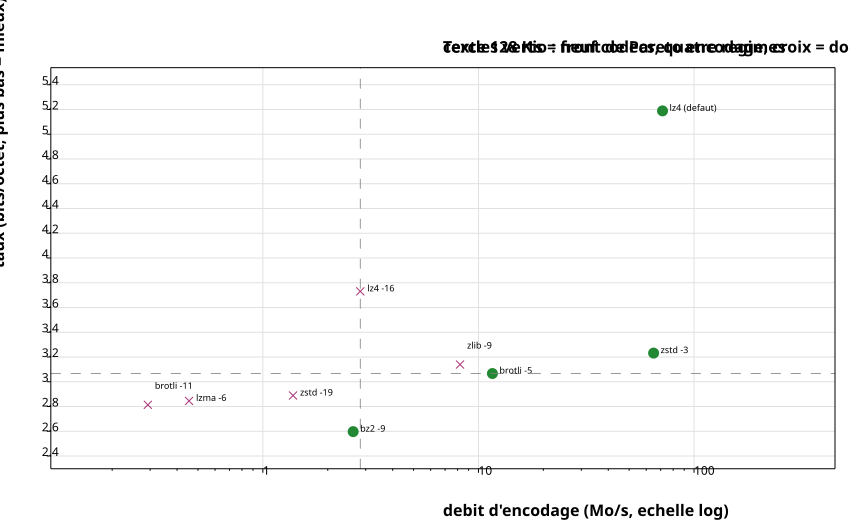

In [7]:
#r "nuget: ScottPlot, 5.0.55"
#nullable enable
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using Microsoft.DotNet.Interactive.Formatting;
using ScottPlot;

/// <summary>Une figure rendue par son SVG : le formateur du noyau sait l'afficher.</summary>
public sealed record Graphique(string Svg);

Formatter.Register<Graphique>((figure, writer) => writer.Write(figure.Svg), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Graphique), "image/svg+xml");

/// <summary>Statistiques utiles au carnet.</summary>
public static class Statistiques
{
    public static double Mediane(IReadOnlyList<double> valeurs)
    {
        var triees = valeurs.OrderBy(v => v).ToList();
        int milieu = triees.Count / 2;
        return triees.Count % 2 == 1
            ? triees[milieu]
            : (triees[milieu - 1] + triees[milieu]) / 2;
    }
}

/// <summary>Graduations d'un axe logarithmique : les donnees sont tracees en log10, les etiquettes retrouvent les puissances de dix.</summary>
public static class Echelle
{
    public static void Logarithmique(Plot figure, IEnumerable<double> valeursLog10)
    {
        double minimum = valeursLog10.Min();
        double maximum = valeursLog10.Max();
        var graduations = new List<Tick>();
        for (int decennie = (int)Math.Floor(minimum); decennie <= (int)Math.Floor(maximum); decennie++)
        {
            for (int k = 2; k <= 9; k++)
            {
                graduations.Add(new Tick(decennie + Math.Log10(k), string.Empty, false));
            }
            graduations.Add(new Tick(
                decennie,
                Math.Pow(10, decennie).ToString("0.#", CultureInfo.InvariantCulture),
                true));
        }
        int suivante = (int)Math.Floor(maximum) + 1;
        graduations.Add(new Tick(
            suivante,
            Math.Pow(10, suivante).ToString("0.#", CultureInfo.InvariantCulture),
            true));
        figure.Axes.Bottom.TickGenerator = new ScottPlot.TickGenerators.NumericManual(graduations.ToArray());
    }

    /// <summary>
    /// Graduations d'un axe lineaire, espaces d'un pas fixe. Les etiquettes sont ecrites en culture
    /// invariante : le noyau tourne ici en culture francaise et afficherait une virgule decimale,
    /// a contre-sens des tableaux.
    /// </summary>
    public static void Lineaire(Plot figure, double minimum, double maximum, double pas)
    {
        var graduations = new List<Tick>();
        int premier = (int)Math.Ceiling(minimum / pas - 1e-9);
        int dernier = (int)Math.Floor(maximum / pas + 1e-9);
        for (int k = premier; k <= dernier; k++)
        {
            double valeur = k * pas;
            graduations.Add(new Tick(valeur, valeur.ToString("0.#", CultureInfo.InvariantCulture), true));
        }
        figure.Axes.Left.TickGenerator = new ScottPlot.TickGenerators.NumericManual(graduations.ToArray());
    }
}

/// <summary>
/// Etiquettes de points : a droite par defaut, decalees d'un cran vers le haut ou le bas quand
/// l'endroit prevu recouvrirait un autre point ou une etiquette deja posee.
/// </summary>
public static class Etiquettes
{
    public static void Placer(
        Plot figure, int largeur, int hauteur, float dx, float dy,
        IEnumerable<(string Texte, Coordinates Position)> elements)
    {
        // La position en pixels d'un point n'est connue qu'apres un rendu, qui fixe la mise en page.
        figure.GetSvgXml(largeur, hauteur);
        var points = elements
            .OrderBy(e => e.Position.X)
            .Select(e => (e.Texte, e.Position, Pixel: figure.GetPixel(e.Position)))
            .ToList();
        var posees = new List<(float Gauche, float Droite, float Haut, float Bas)>();
        float[] ecarts = { 0f, -16f, 16f, -32f, 32f };

        for (int i = 0; i < points.Count; i++)
        {
            var (texte, position, pixel) = points[i];
            float largeurTexte = 4.6f * texte.Length;

            (float Gauche, float Droite, float Haut, float Bas) Boite(float ecart) => (
                pixel.X + dx, pixel.X + dx + largeurTexte,
                pixel.Y + dy + ecart - 5f, pixel.Y + dy + ecart + 5f);

            bool Recouvre(float ecart)
            {
                var boite = Boite(ecart);
                for (int j = 0; j < points.Count; j++)
                {
                    Pixel q = points[j].Pixel;
                    if (j != i && q.X > boite.Gauche - 6 && q.X < boite.Droite + 6
                        && q.Y > boite.Haut - 6 && q.Y < boite.Bas + 6)
                    {
                        return true;
                    }
                }
                foreach (var posee in posees)
                {
                    if (posee.Droite > boite.Gauche && posee.Gauche < boite.Droite
                        && posee.Bas > boite.Haut && posee.Haut < boite.Bas)
                    {
                        return true;
                    }
                }
                return false;
            }

            float retenu = ecarts[^1];
            foreach (float ecart in ecarts)
            {
                if (Recouvre(ecart))
                {
                    continue;
                }
                retenu = ecart;
                break;
            }
            posees.Add(Boite(retenu));

            var etiquette = figure.Add.Text(texte, position.X, position.Y);
            etiquette.LabelFontSize = 9;
            etiquette.Alignment = Alignment.MiddleLeft;
            etiquette.OffsetX = dx;
            etiquette.OffsetY = dy + retenu;
        }
    }
}

double TAUX_MEDIAN = Statistiques.Mediane(RESULTATS.Values.Select(r => r.BitsOctet).ToList());
double VITESSE_MEDIANE = Statistiques.Mediane(RESULTATS.Values.Select(r => r.EncMoS).ToList());

var REGIMES = new Dictionary<string, Func<Mesure, bool>>
{
    ["lent-elu"] = r => r.BitsOctet <= TAUX_MEDIAN && r.EncMoS <= VITESSE_MEDIANE,
    ["lent-modeste"] = r => r.BitsOctet > TAUX_MEDIAN && r.EncMoS <= VITESSE_MEDIANE,
    ["rapide-elu"] = r => r.BitsOctet <= TAUX_MEDIAN && r.EncMoS > VITESSE_MEDIANE,
    ["rapide-modeste"] = r => r.BitsOctet > TAUX_MEDIAN && r.EncMoS > VITESSE_MEDIANE,
};

{
    Console.WriteLine(Affichage.F(
        $"mediane du taux : {TAUX_MEDIAN:F4} bits/octet   mediane de vitesse : {VITESSE_MEDIANE:F2} Mo/s"));
    foreach (var (regime, test) in REGIMES)
    {
        var membres = RESULTATS.Where(item => test(item.Value)).OrderBy(item => item.Value.BitsOctet).ToList();
        Console.WriteLine($"\n{regime} ({membres.Count})");
        foreach (var (nom, r) in membres)
        {
            Console.WriteLine(Affichage.F($"   {nom,-14}{r.BitsOctet,7:F4} b/o   {r.EncMoS,8:F2} Mo/s"));
        }
    }

    const int largeurFigure = 850;
    const int hauteurFigure = 520;
    var figure = new Plot();
    var positions = RESULTATS.ToDictionary(
        item => item.Key,
        item => new Coordinates(Math.Log10(item.Value.EncMoS), item.Value.BitsOctet));
    foreach (var (nom, r) in RESULTATS)
    {
        bool dansLeFront = FRONTS[AxeVitesse.Encodage].Contains(nom);
        var point = figure.Add.Scatter(new[] { positions[nom].X }, new[] { r.BitsOctet });
        point.MarkerShape = dansLeFront ? MarkerShape.FilledCircle : MarkerShape.Eks;
        point.MarkerSize = dansLeFront ? 11 : 8;
        point.Color = Color.FromHex(dansLeFront ? "#228833" : "#aa3377");
        point.LineWidth = 0;
    }
    var horizontale = figure.Add.HorizontalLine(TAUX_MEDIAN);
    horizontale.LinePattern = LinePattern.Dashed;
    horizontale.Color = Colors.Grey;
    horizontale.LineWidth = 0.8f;
    var verticale = figure.Add.VerticalLine(Math.Log10(VITESSE_MEDIANE));
    verticale.LinePattern = LinePattern.Dashed;
    verticale.Color = Colors.Grey;
    verticale.LineWidth = 0.8f;

    double[] positionsLog = RESULTATS.Values.Select(r => Math.Log10(r.EncMoS)).ToArray();
    double tauxMin = RESULTATS.Values.Min(r => r.BitsOctet) - 0.3;
    double tauxMax = RESULTATS.Values.Max(r => r.BitsOctet) + 0.35;
    Echelle.Logarithmique(figure, positionsLog);
    figure.Axes.SetLimits(positionsLog.Min() - 0.45, positionsLog.Max() + 0.8, tauxMin, tauxMax);
    figure.Title("Texte 128 Kio : neuf codecs, quatre regimes\n"
        + "cercles verts = front de Pareto encodage, croix = domines");
    figure.XLabel("debit d'encodage (Mo/s, echelle log)");
    figure.YLabel("taux (bits/octet, plus bas = mieux)");
    figure.Grid.MajorLineColor = Color.FromHex("#e0e0e0");
    Echelle.Lineaire(figure, tauxMin, tauxMax, 0.2);
    Etiquettes.Placer(figure, largeurFigure, hauteurFigure, 7, 0,
        RESULTATS.Select(item => (item.Key, positions[item.Key])));
    display(new Graphique(figure.GetSvgXml(largeurFigure, hauteurFigure)));
}


### Lecture du résultat

Ce tableau est le plus fragile du carnet, et c'est ce qu'il apprend.

**La coupe verticale est reproductible.** Les taux sont déterministes : le
même corpus, les mêmes bibliothèques, les mêmes nombres d'octets. La
médiane du taux vaut donc **3,0664 bits/octet à chaque exécution**, et elle
tombe sur le taux de `brotli -5`. Quatre codecs sont sous elle — `bz2 -9`
(2,5970), `brotli -11` (2,8137), `lzma -6` (2,8451), `zstd -19` (2,8889) —,
`brotli -5` la porte exactement (3,0664), et quatre sont au-dessus :
`zlib -9` (3,1393), `zstd -3` (3,2316), `lz4 -16` (3,7304), `lz4 (defaut)`
(5,1887).

**La coupe horizontale ne l'est pas.** Une médiane calculée sur neuf points
tombe sur un point, et ce point est ici `lz4 -16` lui-même : son débit
d'encodage est la médiane, et le test range l'égalité du côté « lent ».
Rien ne bascule dans cette exécution — ses voisins sous la médiane (`bz2
-9`, puis `zstd -19`) et son premier voisin au-dessus (`zlib -9`) restent
chacun de leur côté, `bz2 -9` de peu — mais une médiane de débits n'a aucune
raison de tomber au même endroit sur une autre machine ou à une autre
seconde. Le voisin qui
passera de l'autre côté du seuil changera de quadrant **sans qu'aucune
propriété de son algorithme ait changé**, et **le comptage par régime
n'est pas stable d'une exécution à l'autre** — ce n'est pas un résultat,
c'est une photographie. Les vitesses exactes de cette exécution sont dans
le tableau ci-dessus ; ce sont elles, et non un chiffre recopié ici, qui
situent les points.

**Ce qui survit à la ré-exécution**, et qui est donc la vraie leçon :

- `brotli -11`, `lzma -6` et `zstd -19` sont sous la médiane de taux **et**
  parmi les quatre encodeurs les plus lents : le régime de l'archivage n'est
  pas discutable, il est structurel.
- `zstd -3` et `lz4 (defaut)` sont au-dessus de la médiane de taux **et**
  les deux plus rapides : le régime du transit tient tout autant.
- Tout ce qui est **entre** ces deux familles est arbitré par la
  frontière, donc par le bruit : `bz2 -9` (le meilleur taux, mais un
  encodage lent), `lz4 -16` (le point-médiane), `zlib -9` (DEFLATE au
  maximum de son effort, ni bon ni rapide — trente ans après sa
  spécification, 3,1393 bits/octet) et `brotli -5` sont les cas limites
  qui font basculer le tableau.

Le partage utile n'est donc pas entre quatre quadrants mais entre **deux
familles que la mesure sépare largement**, et une zone mitoyenne où le
classement appartient au seuil. `lz4 -16` y illustre le levier de réglage :
monter son niveau lui fait gagner 28 % de taux (3,7304 contre 5,1887) en
divisant son débit d'encodage par plus de vingt ici — un réglage ne change
pas la nature d'un algorithme, il déplace son point sur la même courbe.

La conséquence pratique dépasse ce tableau : **un quadrant est une grille de
lecture, pas une taxonomie**. Une grille a un seuil, un seuil se choisit, et
un choix de seuil décide du classement quand les points sont proches. C'est
pourquoi la section précédente **calcule** le front de Pareto : un front ne
dépend pas d'un seuil choisi, une grille si.

Le graphique porte l'essentiel : sur une échelle logarithmique en vitesse,
le front vert est une **marche d'escalier** de quatre points. Entre deux
marches, il n'y a rien à gagner — un codec intermédiaire est dominé, et le
choix se fait entre deux marches voisines, jamais au sein d'une marche.


## 8. Le témoin négatif : l'incompressible

Que fait un banc de compression sur des données qu'aucun codec sans perte
ne peut réduire ? Deux réponses sont inacceptables : qu'il n'y ait rien à
mesurer, et qu'un codec rende moins de 8 bits par octet. La première est
fausse — il y a beaucoup à mesurer ; la seconde serait le signe d'un banc
cassé.


In [8]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Linq;

{
    string entete = Affichage.F($"{"codec",-14}{"bits/octet",11}{"surcout",9}{"enc. Mo/s",11}{"dec. Mo/s",11}");
    Console.WriteLine(entete);
    foreach (var (nom, codec) in CODECS)
    {
        byte[] compresse = codec.Compresser(aleatoire);
        // Le controle sans perte vaut aussi quand la sortie est plus longue que
        // l'entree : allonger la donnee n'excuse pas de l'alterer.
        Affichage.Exiger(
            codec.Decompresser(compresse).AsSpan().SequenceEqual(aleatoire),
            $"aller-retour KO : {nom}");
        // Le surcout est l'ecart a 8 bits/octet : ce que le codec depense en
        // en-tete et en decoupage en blocs quand il ne trouve aucune repetition.
        double bits = 8.0 * compresse.Length / aleatoire.Length;
        string ligne = Affichage.F($"{nom,-14}{bits,11:F4}{bits - 8,9:+0.0000;-0.0000;0.0000}");
        ligne += Affichage.F($"{Banc.Debit(codec.Compresser, aleatoire),11:F2}");
        ligne += Affichage.F($"{Banc.Debit(codec.Decompresser, compresse),11:F2}");
        Console.WriteLine(ligne);
    }
    Console.WriteLine();
    // L'entropie de la source ferme la table : elle frole 8 bits/octet, il n'y
    // a aucune regularite a coder, et chaque codec finit au-dessus de 8.
    Console.WriteLine(Affichage.F($"entropie de la source : {EntropieDeReference.Mesurer(aleatoire):F4} bits/octet"));
}


codec          bits/octet  surcout  enc. Mo/s  dec. Mo/s


lz4 (defaut)       8.0018  +0.0018     200.15    1194.73


zstd -3            8.0012  +0.0012     820.08     361.66


zlib -9            8.0032  +0.0032      22.14    1654.63


brotli -5          8.0005  +0.0005      47.01     422.08


brotli -11         8.0005  +0.0005       1.83     388.69


lzma -6            8.1133  +0.1133       0.95       2.76


bz2 -9             8.0769  +0.0769       1.00       7.48


zstd -19           8.0012  +0.0012       5.29     338.96


lz4 -16            8.0018  +0.0018      18.49     941.62


entropie de la source : 7.9974 bits/octet


### Lecture du résultat

Aucun codec ne descend sous 8,00 bits/octet : le banc est sain, et le
théorème tient. Tous **dépassent** 8,00, d'un surcoût qui va de 0,0005
(`brotli -11`) à 0,113 (`lzma -6`) bit/octet — c'est l'en-tête du format
plus les quelques octets que le codec ajoute quand il ne trouve rien à
retirer. Sur 64 Kio, `bz2` ajoute 0,077 bit/octet, soit environ 630 octets
de structures internes : le prix d'un format à blocs. `lzma` paie le plus
cher, et la section 5 bis en a donné la cause : son conteneur n'a pas
l'échappement de bloc non compressé de `.xz`.

Deux chiffres du tableau méritent qu'on s'y arrête, parce qu'ils sont des
artefacts et non des performances :

- les débits de **décodage** atteignent des valeurs absurdes (plus de
  1 000 Mo/s ici). Un décodeur qui n'a rien à défaire se contente de
  recopier le bloc stocké — on mesure la vitesse de `memcpy`, pas celle du
  codec.
- `lz4` encode l'incompressible **environ trois fois plus vite** que sur le
  texte, pour cette même raison : son chemin rapide détecte l'absence de
  correspondance et stocke.

C'est la raison pour laquelle la section 5 mesurait les débits sur le
**texte** : un banc de compression qui ne mesure que de l'incompressible
mesure la mémoire du système.


## 9. Le levier du niveau : un codec traverse les régimes

Le carnet a présenté chaque codec comme un point. C'est une simplification
commode : la plupart exposent un **niveau**, et le niveau déplace le point
sur la courbe. Zstandard est le cas d'école — un seul algorithme, des
réglages qui vont du transit au quasi-archivage.


 niveau  bits/octet  enc. Mo/s  dec. Mo/s  vs bz2 -9


      1      3.5406      97.48      74.97    +0.9436


      3      3.2316      66.87      63.06    +0.6346


      6      3.1097      22.50      54.09    +0.5127


      9      3.0392      11.49      60.73    +0.4423


     12      3.0092       5.48      46.37    +0.4122


     15      2.9100       2.93      55.59    +0.3130


     19      2.8889       1.27      49.04    +0.2919


     22      2.8889       1.29      48.03    +0.2919


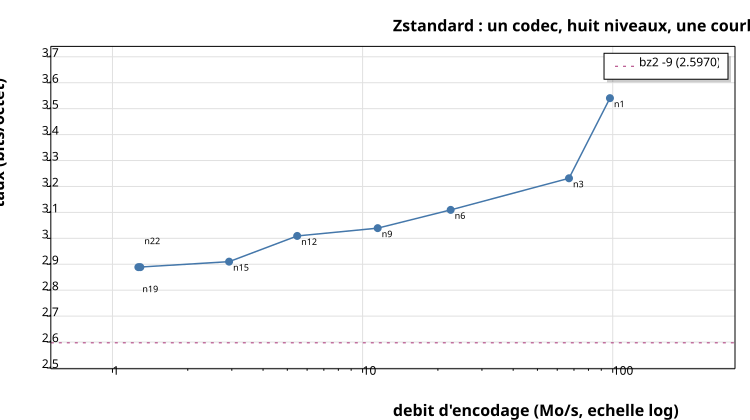

In [9]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Linq;
using Microsoft.DotNet.Interactive.Formatting;
using ScottPlot;

/// <summary>Un point du balayage : un niveau de zstandard et ce qu'il donne sur le texte.</summary>
public sealed record PointBalayage(int Niveau, double BitsOctet, double EncMoS, double DecMoS);

var NIVEAUX = new[] { 1, 3, 6, 9, 12, 15, 19, 22 };
var BALAYAGE = new List<PointBalayage>();

{
    foreach (int niveau in NIVEAUX)
    {
        byte[] compresse = OutilsCompression.Zstd(texte, niveau);
        Affichage.Exiger(
            OutilsCompression.ZstdDecompresse(compresse).AsSpan().SequenceEqual(texte),
            $"aller-retour KO : zstd {niveau}");
        BALAYAGE.Add(new PointBalayage(
            niveau,
            8.0 * compresse.Length / texte.Length,
            Banc.Debit(donnees => OutilsCompression.Zstd(donnees, niveau), texte),
            Banc.Debit(OutilsCompression.ZstdDecompresse, compresse)));
    }

    double reference = RESULTATS["bz2 -9"].BitsOctet;
    string entete = Affichage.F($"{"niveau",7}{"bits/octet",12}{"enc. Mo/s",11}{"dec. Mo/s",11}{"vs bz2 -9",11}");
    Console.WriteLine(entete);
    foreach (var point in BALAYAGE)
    {
        string ligne = Affichage.F($"{point.Niveau,7}{point.BitsOctet,12:F4}{point.EncMoS,11:F2}{point.DecMoS,11:F2}");
        Console.WriteLine(ligne + Affichage.F($"{point.BitsOctet - reference,11:+0.0000;-0.0000;0.0000}"));
    }

    const int largeurFigure = 750;
    const int hauteurFigure = 420;
    var figure = new Plot();
    double[] debits = BALAYAGE.Select(p => p.EncMoS).ToArray();
    double[] taux = BALAYAGE.Select(p => p.BitsOctet).ToArray();
    double[] positionsLog = Array.ConvertAll(debits, Math.Log10);
    var courbe = figure.Add.ScatterLine(positionsLog, taux);
    courbe.Color = Color.FromHex("#4477aa");
    courbe.LineWidth = 1.5f;
    courbe.MarkerShape = MarkerShape.FilledCircle;
    courbe.MarkerSize = 8;
    var ligneReference = figure.Add.HorizontalLine(reference);
    ligneReference.LinePattern = LinePattern.Dotted;
    ligneReference.Color = Color.FromHex("#aa3377");
    ligneReference.LineWidth = 1;
    ligneReference.LegendText = Affichage.F($"bz2 -9 ({reference:F4})");

    // La borne basse laisse voir la ligne de reference : la seule marge sur les taux la placerait hors du cadre.
    double tauxMin = Math.Min(taux.Min() - 0.12, reference - 0.1);
    double tauxMax = taux.Max() + 0.2;
    Echelle.Logarithmique(figure, positionsLog);
    figure.Axes.SetLimits(positionsLog.Min() - 0.35, positionsLog.Max() + 0.5, tauxMin, tauxMax);
    figure.Title("Zstandard : un codec, huit niveaux, une courbe");
    figure.XLabel("debit d'encodage (Mo/s, echelle log)");
    figure.YLabel("taux (bits/octet)");
    figure.Grid.MajorLineColor = Color.FromHex("#e0e0e0");
    Echelle.Lineaire(figure, tauxMin, tauxMax, 0.1);
    figure.ShowLegend();
    figure.Legend.Alignment = Alignment.UpperRight;
    Etiquettes.Placer(figure, largeurFigure, hauteurFigure, 4, 9,
        BALAYAGE.Select(p => ("n" + p.Niveau, new Coordinates(Math.Log10(p.EncMoS), p.BitsOctet))));
    display(new Graphique(figure.GetSvgXml(largeurFigure, hauteurFigure)));
}


### Lecture du résultat

La courbe a la forme attendue — le taux s'améliore quand la vitesse chute —
mais elle porte deux enseignements qu'aucun tableau de benchmarks
commercial ne donne :

- **Le rendement s'effondre bien avant le dernier niveau.** Entre le
  niveau 1 et le niveau 6, zstd gagne 0,43 bit/octet (3,5406 → 3,1097) en
  abandonnant l'essentiel de sa vitesse d'encodage — la colonne `enc. Mo/s`
  du tableau donne le rapport exact pour cette exécution. Entre le
  niveau 15 et le niveau 22, il gagne **0,02 bit/octet** (2,9100 → 2,8889),
  c'est-à-dire presque rien, en payant encore un facteur sur ce qui lui
  restait. Le dernier cran du réglage coûte cher pour presque rien : c'est
  la définition d'un réglage mal choisi.
- **Les niveaux 19 et 22 rendent la même taille** sur ce corpus — à
  128 Kio, la fenêtre et les structures de niveau 22 n'ont plus rien à
  exploiter que le niveau 19 n'ait déjà trouvé. Deux points du tableau,
  un seul point de la courbe.

Et le point qui referme le carnet : **aucun niveau de zstd n'atteint `bz2
-9` en taux**. La colonne « vs bz2 -9 » reste positive de bout en bout.
Zstandard gagne partout ailleurs — en vitesse de décodage, en réglabilité,
en ratio vitesse/taux — mais sur 128 Kio de français, la fenêtre de bzip2
et son codage par blocs restent devant. Ce n'est pas un classement
définitif : c'est la démonstration que « meilleur codec » n'a pas de sens
hors d'un corpus et d'un axe.

### Ce qu'OpenZL apporte, et pourquoi il n'est pas au banc

Le carnet Python cite OpenZL 0.3.0 comme représentant de l'état de l'art
2025-2026. Trois apports sont documentés par sa spécification, et aucun
n'est mesuré ici : aucun binding Python n'existe, et la liaison .NET
évoquée en section 2 n'est pas référencée — ce jumeau garde le protocole
du carnet Python :

- **Offset Encoding V-optimal** — coder les décalages LZ par un code
  optimal plutôt qu'un code fixe, ce qui attaque précisément le surcoût que
  la section 8 mesure sur les blocs courts ;
- **FieldLZ** — séparer les données en champs (colonnes d'un
  enregistrement) et compresser chaque champ avec son propre codec, la
  réponse au régime `structure` de la section 3 ;
- **PivCo-Huffman** — Huffman sur arbres d'ondelettes pour un décodage
  SIMD, c'est-à-dire l'attaque du mur de la section 6 : améliorer le
  décodage sans payer le taux.

Ce sont des directions, pas des chiffres. Le carnet les nomme pour que le
lecteur sache ce qui manque, sans leur prêter une mesure qu'il n'a pas
faite.


## 10. Exercices

Trois exercices, du calcul au diagnostic. Chaque squelette retourne `null`
tant qu'il n'est pas complété : le carnet s'exécute de bout en bout dans cet
état. Il en va de même des deux squelettes posés plus haut — l'entropie
(section 3) et le front de Pareto (section 6) : les valeurs que le carnet
commente viennent d'une implémentation de validation distincte, chaque
exercice garde son propre `// TODO etudiant`.


In [10]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Linq;

// Exercice 1 -- Le front de Pareto a trois axes
//
// Le carnet a calcule deux fronts : (taux, encodage) et (taux, decodage). Un archiviste, lui, a
// trois contraintes : il veut le meilleur taux, un encodage supportable ET un decodage
// supportable. Le front a trois dimensions n'est plus une marche d'escalier : un codec peut y
// entrer en etant mauvais sur un axe, du moment qu'aucun autre ne le bat sur les trois.

/// <summary>
/// TODO etudiant : codecs non domines sur (taux, encodage, decodage), restreints a ceux qui
/// passent les deux seuils de vitesse.
/// </summary>
public static List<string>? FrontTroisAxes(
    Dictionary<string, Mesure> resultats, double seuilEnc, double seuilDec)
{
    // TODO etudiant : garder les codecs dont l'encodage atteint seuilEnc Mo/s et le decodage
    // seuilDec Mo/s, puis retirer ceux qui sont domines : un codec A en domine un autre B si A a un
    // taux meilleur ou egal, un encodage et un decodage rapides ou egaux, avec au moins une
    // inegalite stricte.
    // Indice : comparer toutes les paires est la bonne facon d'ecrire la definition -- il n'y a
    // que neuf codecs.
    // Indice : avec les seuils 10 Mo/s et 50 Mo/s, la reponse contient plus d'un codec : le front
    // a trois axes est plus permissif que celui a deux.
    return null;
}

{
    var resultat = FrontTroisAxes(RESULTATS, 10.0, 50.0);
    if (resultat is null)
    {
        Console.WriteLine("Exercice a completer : FrontTroisAxes");
    }
    else
    {
        Console.WriteLine(
            $"front a trois axes (enc >= 10 Mo/s, dec >= 50 Mo/s) : {resultat.Count} codecs");
        foreach (string nom in resultat)
        {
            var r = RESULTATS[nom];
            Console.WriteLine(Affichage.F($"   {nom,-14}{r.BitsOctet,7:F4} b/o  {r.EncMoS,8:F2}  {r.DecMoS,8:F2}"));
        }
    }
}


Exercice a completer : FrontTroisAxes


In [11]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Linq;

// Exercice 2 -- Le corpus change le classement
//
// La section 3 predit que sur `structure` (entropie marginale presque maximale, redondance
// purement positionnelle), les codecs a forte couche LZ passent devant et que lz4 decroche.
// Verifiez-le, et quantifiez l'ecart avec le classement obtenu sur le texte.

/// <summary>
/// TODO etudiant : noms des codecs tries par taux croissant sur le corpus donne, apres
/// verification de chaque aller-retour.
/// </summary>
public static List<string>? Classement(byte[] donnees, Dictionary<string, Codec> codecs)
{
    // TODO etudiant : pour chaque codec, compresser `donnees`, verifier que la decompression rend
    // l'original, puis trier les noms par taux croissant.
    // Indice : le classement ne demande que la taille compressee ; le debit ne sert qu'a la
    // vitesse.
    // Indice : `structure` fait 131 072 octets, comme le texte -- les deux classements se
    // comparent sans normalisation.
    return null;
}

{
    var resultat = Classement(structure, CODECS);
    if (resultat is null)
    {
        Console.WriteLine("Exercice a completer : Classement");
    }
    else
    {
        Console.WriteLine("classement sur 'structure' (bits/octet croissant) :");
        for (int rang = 0; rang < resultat.Count; rang++)
        {
            Console.WriteLine($"   {rang + 1}. {resultat[rang]}");
        }
    }
}


Exercice a completer : Classement


In [12]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Linq;

// Exercice 3 -- Le seuil ou un codec cesse d'etre utile
//
// Sur l'incompressible, tous les codecs depassent 8 bits/octet : ils RALONGENT les donnees. Un
// service qui compresse a l'aveugle paie donc pour rien, et parfois paie plus cher que de ne rien
// faire. Mesurez a partir de quelle part de texte chaque codec redevient gagnant.

/// <summary>
/// TODO etudiant : taux (bits/octet) du codec sur des melanges de texte et d'octets uniformes,
/// pour chaque fraction de texte de `fractions`.
/// </summary>
public static Dictionary<double, double>? SeuilPerdant(Codec codec, double[] fractions)
{
    // TODO etudiant : pour chaque fraction f de `fractions` (part de texte), construire un melange
    // de texte et d'octets uniformes, le compresser avec `codec`, et ranger le taux obtenu sous la
    // cle f.
    // Indice : le melange prend ses f premiers octets dans `texte` et les suivants dans
    // `aleatoire`.
    // Indice : le temoin aleatoire ne compte que 65 536 octets ; sous une part de texte de 50 %,
    // un melange qui se contente de concatener est donc plus court que le corpus texte -- ou bien
    // tirez les octets manquants d'un second generateur seede.
    // Indice : le croisement de la droite a 8 bits/octet est le seuil cherche ; un codec qui
    // stocke (lz4) reste sous 8 bien plus longtemps qu'un codec a en-tete lourd (bz2).
    return null;
}

{
    var resultat = SeuilPerdant(CODECS["bz2 -9"], new[] { 0.0, 0.25, 0.5, 0.75, 1.0 });
    if (resultat is null)
    {
        Console.WriteLine("Exercice a completer : SeuilPerdant");
    }
    else
    {
        foreach (var (fraction, bits) in resultat.OrderBy(item => item.Key))
        {
            Console.WriteLine(Affichage.F($"part de texte {fraction,4:P0} : {bits:F4} bits/octet"));
        }
    }
}


Exercice a completer : SeuilPerdant


## À retenir

- **Un codec n'est pas un score, c'est un point.** Le classer sur le taux
  seul, ou sur la vitesse seule, produit une réponse fausse dans les deux
  cas. Le carnet a calculé le front de Pareto plutôt que de désigner un
  vainqueur, et le front **change de membres** selon qu'on regarde la
  vitesse d'encodage ou celle de décodage.
- **La couche LZ explique l'écart au carnet 04.** Les codeurs entropiques
  nus collent à l'entropie des octets (4,62 bits/octet sur le texte) ; les
  codecs de production passent 2 bits **sous** cette valeur parce qu'ils ne
  transmettent pas les octets dont on mesure l'entropie. Le carnet 03 avait
  raison avant le carnet 04, et les deux ne se contredisent pas : ils
  mesurent deux choses.
- **L'âge d'un algorithme ne prédit pas son rang.** Sur 128 Kio de
  français, `bz2` (1996) bat `brotli -11`, `lzma -6` et `zstd -19` en taux
  **et** en vitesse d'encodage. Ce n'est pas un verdict universel : c'est
  un résultat sur un corpus, et il suffit de changer de corpus (exercice 2)
  pour le voir bouger.
- **Le niveau est un levier, pas une qualité.** Un même codec traverse
  plusieurs régimes selon son réglage — et le dernier cran coûte cher pour
  presque rien : entre les niveaux 15 et 22 de zstd, 0,02 bit/octet pour
  plus de deux fois moins de vitesse.
- **Un banc se vérifie avant de mesurer.** Aller-retour octet-exact
  asserté, débit par répétition, et lecture critique des chiffres absurdes :
  les débits de décodage au-delà de 1 000 Mo/s sur l'incompressible
  mesurent `memcpy`, pas un codec.
- **Deux implémentations, deux contrats.** Ce jumeau C# mesure les mêmes
  algorithmes par d'autres bibliothèques : les taux y sont identiques quand
  les octets le sont (bzip2, brotli, zstandard), et l'écart est chiffré
  quand le conteneur diffère (LZMA1 contre `.xz`, trame LZ4) ou quand
  l'implémentation change (zlib-ng du runtime contre zlib). Un chiffre sans
  son implémentation n'est pas un résultat.

## Vérifiez votre compréhension

1. Sur les 128 Kio de français, quel codec de 1996 bat `brotli -11`, `lzma -6` et `zstd -19` — et sur quels deux axes ?

<details><summary>Réponse</summary>

`bz2` (1996), en taux **et** en vitesse d'encodage (section 5). Ce n'est pas
un verdict universel : un résultat sur un corpus, que l'exercice 2 fait
bouger en changeant de corpus.

</details>

2. Pourquoi les codecs de production passent-ils 2 bits/octet **sous** l'entropie des octets (4,62 bits/octet sur le texte) ?

<details><summary>Réponse</summary>

Parce qu'ils ne transmettent pas les octets dont on mesure l'entropie : la
couche LZ remplace des octets par des couples avant le codage (section 5 bis).
Le carnet 04 mesurait les codeurs entropiques nus — les deux carnets
mesurent deux choses.

</details>

3. `zstd`, niveaux 15 → 22 : qu'achète le dernier cran ?

<details><summary>Réponse</summary>

0,02 bit/octet pour plus de deux fois moins de vitesse (section 9) — le
niveau est un levier, pas une qualité.

</details>

4. Sur l'incompressible, que mesurent réellement les débits de décodage qui dépassent 1 000 Mo/s ?

<details><summary>Réponse</summary>

`memcpy`, pas un codec : c'est le témoin négatif du banc (section 8) — les
chiffres absurdes se lisent, ils ne se publient pas.

</details>

## Pour aller plus loin

- **Carnet suivant** : [Compression-05 — compression des modèles](Compression-05-MLCompression-Python.ipynb) —
  quantifier, élaguer, distiller : la compression change de côté, ce sont
  les poids du réseau qu'on comprime.
- **Carnet voisin** : [Compression-04 — ANS](Compression-04-ANS-CSharp.ipynb), les tables que ces
  codecs déploient à grande échelle.
- **Jumeau Python** : [Compression-04b — codecs et front de Pareto](Compression-04b-CodecsSOTA-Pareto-Python.ipynb),
  la même mesure avec les bibliothèques C de Python.
- **Hors banc mais dans le dépôt** : l'encart OpenZL de la section 9 dit ce
  qu'il apporte et pourquoi il n'est pas mesuré au banc.

> *Provenance : sous-série `Compression`, carnet 4b — jumeau C# du carnet Python de même numéro.*
